# Notebook 02: Exploratory Data Analysis

## AI Revenue Optimization & Conversion Intelligence System for Nattoguard

This notebook focuses on exploring customer behavior patterns in the cleaned Online Shoppers Purchasing Intention dataset.

The goal of this analysis is to identify patterns related to customer purchase behavior, including the effect of visitor type, product page engagement, bounce rates, exit rates, page values, month, and weekend activity.

These insights will later support:

- Machine learning feature selection
- Customer segmentation
- Business decision rules
- LLM-generated marketing messages
- Final slide deck visualizations

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
DATA_PATH = Path("../data/processed/online_shoppers_cleaned.csv")
FIGURES_PATH = Path("../outputs/figures")
SLIDE_ASSETS_PATH = Path("../outputs/slide_assets")

FIGURES_PATH.mkdir(parents=True, exist_ok=True)
SLIDE_ASSETS_PATH.mkdir(parents=True, exist_ok=True)

print("Paths prepared successfully.")

Paths prepared successfully.


In [3]:
df = pd.read_csv(DATA_PATH)

print("Cleaned dataset loaded successfully.")
print("Shape:", df.shape)

df.head()

Cleaned dataset loaded successfully.
Shape: (12205, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12205 entries, 0 to 12204
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12205 non-null  int64  
 1   Administrative_Duration  12205 non-null  float64
 2   Informational            12205 non-null  int64  
 3   Informational_Duration   12205 non-null  float64
 4   ProductRelated           12205 non-null  int64  
 5   ProductRelated_Duration  12205 non-null  float64
 6   BounceRates              12205 non-null  float64
 7   ExitRates                12205 non-null  float64
 8   PageValues               12205 non-null  float64
 9   SpecialDay               12205 non-null  float64
 10  Month                    12205 non-null  str    
 11  OperatingSystems         12205 non-null  int64  
 12  Browser                  12205 non-null  int64  
 13  Region                   12205 non-null  int64  
 14  TrafficType              12205 no

### Dataset Overview

The cleaned dataset contains customer session-level behavioral features and the target variable `Revenue`.

The target variable indicates whether a user session resulted in a purchase. This makes the project suitable for conversion prediction and customer intent analysis.

In [5]:
revenue_counts = df["Revenue"].value_counts()
revenue_percentages = df["Revenue"].value_counts(normalize=True) * 100

revenue_summary = pd.DataFrame({
    "Count": revenue_counts,
    "Percentage": revenue_percentages.round(2)
})

revenue_summary

,Count,Percentage
Revenue,,
False,10297,84.37
True,1908,15.63


### Revenue Distribution Insight

The dataset is imbalanced because most customer sessions did not result in revenue, while only a smaller percentage led to a purchase. This reflects a realistic e-commerce situation where many visitors browse a website, but only a limited number complete a transaction.

Because of this imbalance, model performance should not be evaluated using accuracy alone. A model could achieve high accuracy by mostly predicting the majority class, which is non-purchase sessions. Therefore, evaluation metrics such as precision, recall, F1-score, and ROC-AUC will be used later to better assess how well the model identifies potential buyers.

In [7]:
revenue_summary.to_csv(SLIDE_ASSETS_PATH / "revenue_distribution_summary.csv")

In [8]:
visitor_revenue = pd.crosstab(
    df["VisitorType"],
    df["Revenue"],
    normalize="index"
) * 100

visitor_revenue = visitor_revenue.round(2)

visitor_revenue

Revenue,False,True
VisitorType,,
New_Visitor,75.07,24.93
Other,80.25,19.75
Returning_Visitor,85.91,14.09


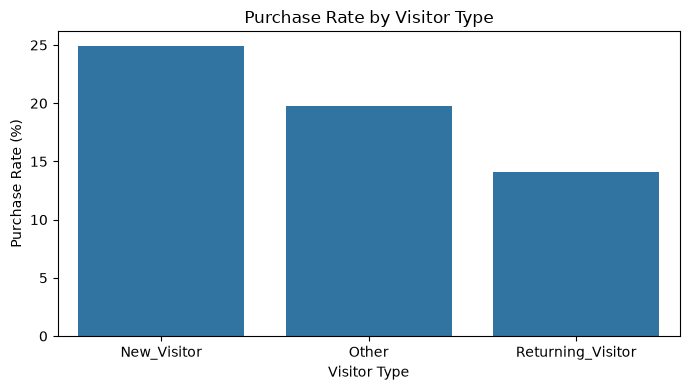

In [9]:
visitor_revenue_plot = visitor_revenue.reset_index()

plt.figure(figsize=(7, 4))
sns.barplot(data=visitor_revenue_plot, x="VisitorType", y=True)
plt.title("Purchase Rate by Visitor Type")
plt.xlabel("Visitor Type")
plt.ylabel("Purchase Rate (%)")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "purchase_rate_by_visitor_type.png", dpi=300)
plt.show()

### Visitor Type Insight

Visitor type is important for conversion analysis because returning visitors and new visitors may behave differently. If returning visitors show a higher purchase rate, the business can prioritize retargeting and personalized follow-up campaigns.

In [10]:
month_revenue = pd.crosstab(
    df["Month"],
    df["Revenue"],
    normalize="index"
) * 100

month_revenue = month_revenue.round(2)
month_revenue

Revenue,False,True
Month,,
Aug,82.45,17.55
Dec,87.34,12.66
Feb,98.34,1.66
Jul,84.72,15.28
June,89.82,10.18
Mar,89.68,10.32
May,89.04,10.96
Nov,74.51,25.49
Oct,79.05,20.95


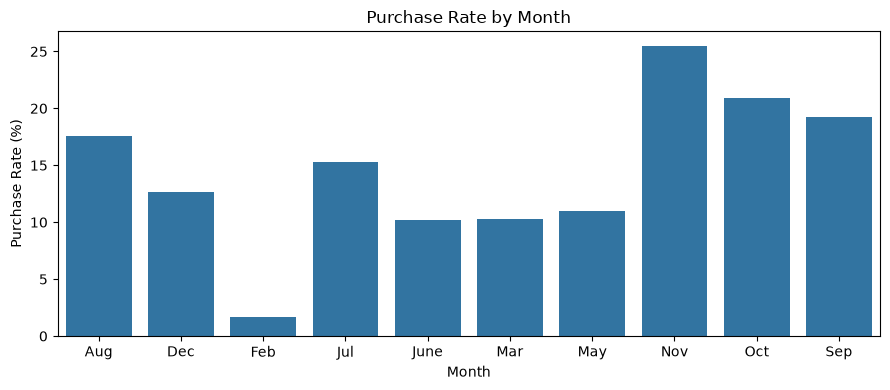

In [11]:
month_revenue_plot = month_revenue.reset_index()

plt.figure(figsize=(9, 4))
sns.barplot(data=month_revenue_plot, x="Month", y=True)
plt.title("Purchase Rate by Month")
plt.xlabel("Month")
plt.ylabel("Purchase Rate (%)")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "purchase_rate_by_month.png", dpi=300)
plt.show()

### Monthly Purchase Pattern Insight

Month-based analysis helps identify seasonal patterns in purchase behavior. This can support campaign planning, product promotions, and marketing calendar decisions.

In [12]:
weekend_revenue = pd.crosstab(
    df["Weekend"],
    df["Revenue"],
    normalize="index"
) * 100

weekend_revenue = weekend_revenue.round(2)
weekend_revenue

Revenue,False,True
Weekend,,
False,84.92,15.08
True,82.55,17.45


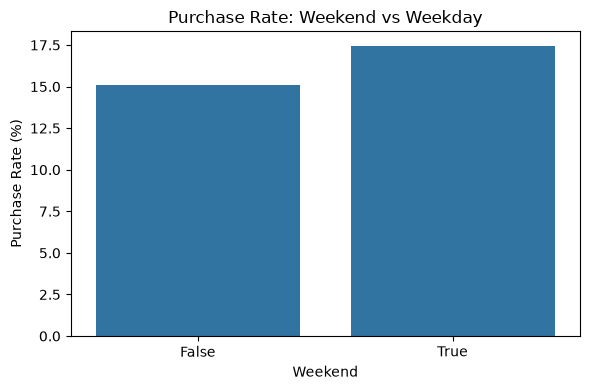

In [13]:
weekend_revenue_plot = weekend_revenue.reset_index()

plt.figure(figsize=(6, 4))
sns.barplot(data=weekend_revenue_plot, x="Weekend", y=True)
plt.title("Purchase Rate: Weekend vs Weekday")
plt.xlabel("Weekend")
plt.ylabel("Purchase Rate (%)")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "purchase_rate_weekend_vs_weekday.png", dpi=300)
plt.show()

### Weekend Behavior Insight

Weekend behavior can help determine whether campaigns should be scheduled differently across weekdays and weekends. If weekend sessions show stronger purchase rates, weekend promotions or reminders may be useful.

In [14]:
product_engagement_summary = df.groupby("Revenue")[[
    "ProductRelated",
    "ProductRelated_Duration"
]].mean().round(2)

product_engagement_summary

,ProductRelated,ProductRelated_Duration
Revenue,,
False,29.05,1082.98
True,48.21,1876.21


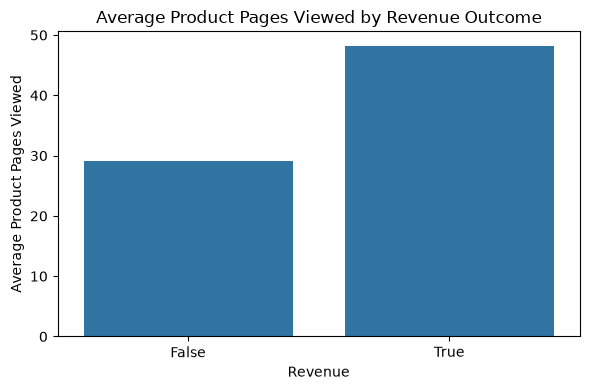

In [15]:
product_engagement_plot = product_engagement_summary.reset_index()

plt.figure(figsize=(6, 4))
sns.barplot(data=product_engagement_plot, x="Revenue", y="ProductRelated")
plt.title("Average Product Pages Viewed by Revenue Outcome")
plt.xlabel("Revenue")
plt.ylabel("Average Product Pages Viewed")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "avg_product_pages_by_revenue.png", dpi=300)
plt.show()

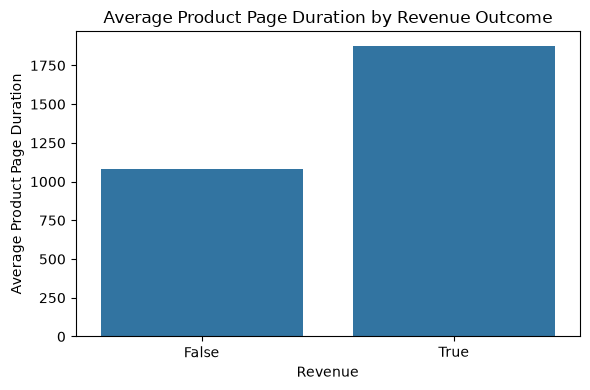

In [16]:
plt.figure(figsize=(6, 4))
sns.barplot(data=product_engagement_plot, x="Revenue", y="ProductRelated_Duration")
plt.title("Average Product Page Duration by Revenue Outcome")
plt.xlabel("Revenue")
plt.ylabel("Average Product Page Duration")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "avg_product_duration_by_revenue.png", dpi=300)
plt.show()

### Product Engagement Insight

Product-related page visits and product page duration are important behavioral indicators. Customers who spend more time exploring product pages may show stronger purchase intent. This insight supports the use of product engagement features in the conversion prediction model.

In [17]:
engagement_quality_summary = df.groupby("Revenue")[[
    "BounceRates",
    "ExitRates",
    "PageValues"
]].mean().round(4)

engagement_quality_summary

,BounceRates,ExitRates,PageValues
Revenue,,,
False,0.0232,0.0455,2.0000
True,0.0051,0.0196,27.2645


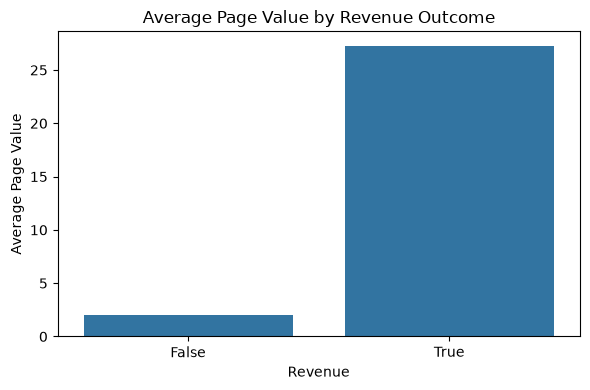

In [18]:
engagement_quality_plot = engagement_quality_summary.reset_index()

plt.figure(figsize=(6, 4))
sns.barplot(data=engagement_quality_plot, x="Revenue", y="PageValues")
plt.title("Average Page Value by Revenue Outcome")
plt.xlabel("Revenue")
plt.ylabel("Average Page Value")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "avg_page_value_by_revenue.png", dpi=300)
plt.show()

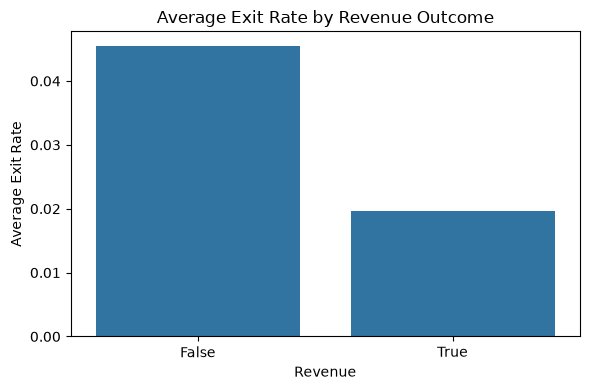

In [19]:
plt.figure(figsize=(6, 4))
sns.barplot(data=engagement_quality_plot, x="Revenue", y="ExitRates")
plt.title("Average Exit Rate by Revenue Outcome")
plt.xlabel("Revenue")
plt.ylabel("Average Exit Rate")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "avg_exit_rate_by_revenue.png", dpi=300)
plt.show()

### Engagement Quality Insight

Page value, bounce rate, and exit rate are important indicators of conversion quality. Higher page values may indicate stronger purchase intent, while higher exit or bounce rates may indicate friction or weak engagement in the customer journey.

In [20]:
df_corr = df.copy()

df_corr["Revenue"] = df_corr["Revenue"].astype(int)
df_corr["Weekend"] = df_corr["Weekend"].astype(int)

numeric_df = df_corr.select_dtypes(include=["int64", "float64"])

correlation_matrix = numeric_df.corr()

correlation_matrix["Revenue"].sort_values(ascending=False)

Revenue                    1.000000
PageValues                 0.491894
ProductRelated             0.156042
ProductRelated_Duration    0.150077
Administrative             0.136330
Informational              0.093626
Administrative_Duration    0.091768
Informational_Duration     0.069358
Weekend                    0.027729
Browser                    0.024052
TrafficType               -0.005618
Region                    -0.012725
OperatingSystems          -0.014927
SpecialDay                -0.083601
BounceRates               -0.145091
ExitRates                 -0.204320
Name: Revenue, dtype: float64

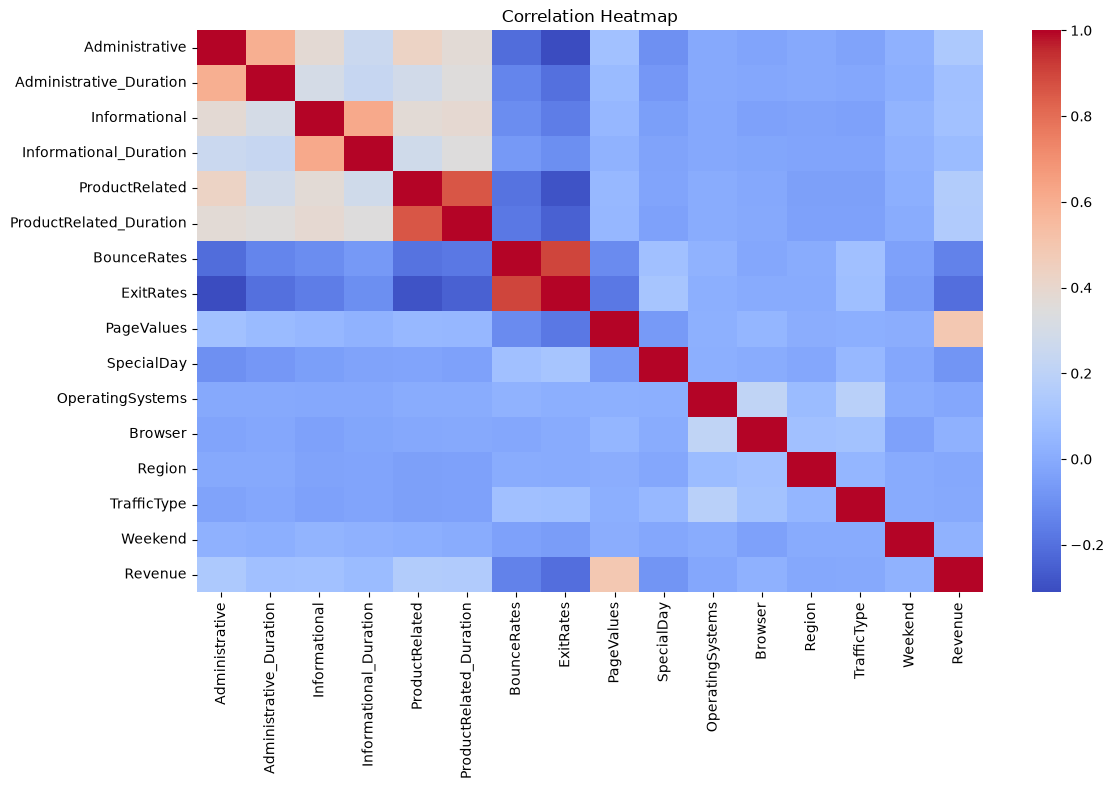

In [21]:
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, cmap="coolwarm", annot=False)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "correlation_heatmap.png", dpi=300)
plt.show()

### Correlation Insight

Correlation analysis helps identify numerical features that are more strongly related to purchase behavior. These insights will support feature selection and model interpretation in the machine learning stage.

In [22]:
revenue_correlations = correlation_matrix["Revenue"].sort_values(ascending=False).drop("Revenue")

top_revenue_correlations = revenue_correlations.head(10)

top_revenue_correlations

PageValues                 0.491894
ProductRelated             0.156042
ProductRelated_Duration    0.150077
Administrative             0.136330
Informational              0.093626
Administrative_Duration    0.091768
Informational_Duration     0.069358
Weekend                    0.027729
Browser                    0.024052
TrafficType               -0.005618
Name: Revenue, dtype: float64

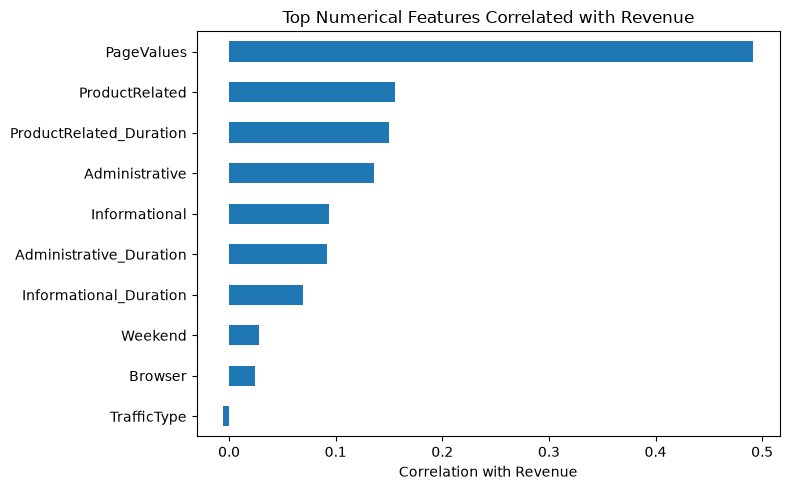

In [23]:
plt.figure(figsize=(8, 5))
top_revenue_correlations.sort_values().plot(kind="barh")
plt.title("Top Numerical Features Correlated with Revenue")
plt.xlabel("Correlation with Revenue")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "top_features_correlated_with_revenue.png", dpi=300)
plt.show()

### Feature Relevance Insight

The most revenue-related numerical features provide early guidance on which features may be useful for the machine learning model. These features will later be compared with model-based feature importance.

In [24]:
business_insights = pd.DataFrame([
    {
        "Area": "Visitor Type",
        "Insight": "Different visitor types may show different purchase rates.",
        "Business Use": "Personalize campaigns for new and returning visitors."
    },
    {
        "Area": "Product Engagement",
        "Insight": "Product page views and duration can indicate purchase intent.",
        "Business Use": "Use product engagement as an input for conversion prediction."
    },
    {
        "Area": "Page Value",
        "Insight": "Higher page value is associated with stronger purchase behavior.",
        "Business Use": "Prioritize users with high page value for targeted offers."
    },
    {
        "Area": "Exit and Bounce Rates",
        "Insight": "High exit or bounce rates may indicate funnel friction.",
        "Business Use": "Trigger retargeting or educational content for users who leave early."
    },
    {
        "Area": "Month and Weekend",
        "Insight": "Time-based patterns can influence purchase behavior.",
        "Business Use": "Support campaign scheduling and seasonal promotions."
    }
])

business_insights

,Area,Insight,Business Use
0,Visitor Type,Different visitor types may show different pur...,Personalize campaigns for new and returning vi...
1,Product Engagement,Product page views and duration can indicate p...,Use product engagement as an input for convers...
2,Page Value,Higher page value is associated with stronger ...,Prioritize users with high page value for targ...
3,Exit and Bounce Rates,High exit or bounce rates may indicate funnel ...,Trigger retargeting or educational content for...
4,Month and Weekend,Time-based patterns can influence purchase beh...,Support campaign scheduling and seasonal promo...


In [25]:
business_insights.to_csv(SLIDE_ASSETS_PATH / "eda_business_insights.csv", index=False)

print("Business insights saved successfully.")

Business insights saved successfully.


## EDA Conclusion

The exploratory data analysis shows that customer purchase behavior is influenced by engagement patterns, visitor type, page value, exit rates, bounce rates, and time-related factors such as month and weekend activity.

These findings support the next stage of the project: building a machine learning model to predict customer purchase probability.

From a business perspective, the EDA confirms that customer behavior data can be used to identify high-intent users, detect potential drop-off patterns, and support personalized marketing actions for Nattoguard.